# Задача № 3. Классификация самолётов с помощью мультимодальных LLM

**Цель:** по фотографии определить класс самолёта («Военный» / «Гражданский») и сравнить качество **Qwen2.5-VL 3B** и **Gemma 3 4B**. Запросы отправляются программно через локальный **Ollama API**.

**Выборка:** 30 изображений Wikimedia Commons (15 + 15), из которых 21 заранее отмечено как сложный случай. Источники, эталонные метки и обоснования указаны в `data/aircraft_manifest.csv`.


## 1. Настройки эксперимента

Модели запускаются последовательно, чтобы снизить нагрузку на 8 ГБ RAM. Уже сохранённые ответы повторно не запрашиваются. Значения классов в отчёте и графиках приводятся на русском языке.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
import aircraft_eval as ae

DOWNLOAD_IMAGES = True
RUN_INFERENCE = True
MAX_IMAGES = 30
FORCE_RERUN = False
MODEL_IDS = ['qwen2.5vl:3b', 'gemma3:4b']

ru_label = ae.LABELS_RU
ru_difficulty = ae.DIFFICULTY_RU

## 2. Состав выборки

Эталонный класс определён по назначению конкретного борта (не только по форме самолёта). Примеры с внешне похожими гражданскими и военными самолётами намеренно включены в выборку.

,№,Самолёт,Класс,Сложность,Обоснование,Источник
0,001,Boeing 737-800 (United Airlines),Гражданский,Простой,Пассажирский лайнер авиакомпании United Airlines.,https://commons.wikimedia.org/wiki/File:United...
1,002,Airbus A320 (Airbus Industries),Гражданский,Простой,Гражданский тестовый A320 в окраске производит...,https://commons.wikimedia.org/wiki/File:Airbus...
2,003,Boeing 747-400BCF (Saudia Cargo),Гражданский,Сложный,Коммерческий грузовой самолёт; грузовой не озн...,https://commons.wikimedia.org/wiki/File:Boeing...
3,004,Cessna 172,Гражданский,Простой,"Частный/учебный лёгкий гражданский самолёт, ра...",https://commons.wikimedia.org/wiki/File:Cessna...
4,005,Gulfstream G650 (business jet),Гражданский,Сложный,"Частный бизнес-джет, внешне может напоминать п...",https://commons.wikimedia.org/wiki/File:David_...
5,006,Pilatus PC-12 (Fly 7 Executive Aviation),Гражданский,Сложный,"Одномоторный бизнес-самолёт, похожий на военны...",https://commons.wikimedia.org/wiki/File:Pilatu...
6,007,Beechcraft King Air (private),Гражданский,Сложный,Частный двухмоторный King Air; конструктивно п...,https://commons.wikimedia.org/wiki/File:N77CE_...
7,008,Air Tractor AT-802 (agricultural),Гражданский,Сложный,Сельскохозяйственный самолёт специального назн...,https://commons.wikimedia.org/wiki/File:Air_Tr...
8,009,Canadair CL-415 (Italian firefighting),Гражданский,Сложный,"Пожарный самолёт Италии: спасательная, а не во...",https://commons.wikimedia.org/wiki/File:I-DPCN...
9,010,Douglas DC-3 (DesertAir),Гражданский,Сложный,Исторический транспортный самолёт в гражданско...,https://commons.wikimedia.org/wiki/File:Desert...


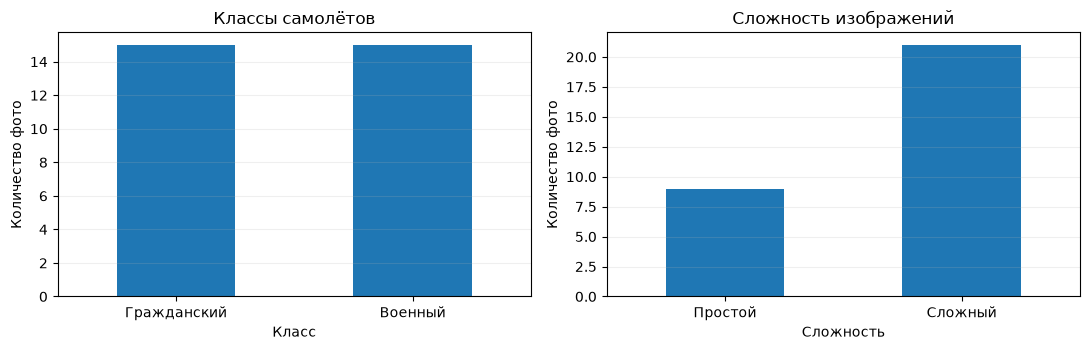

In [4]:
df = ae.load_manifest()
view = df[['id', 'aircraft', 'label', 'difficulty', 'rationale', 'source_page']].copy()
view['label'] = view['label'].map(ru_label)
view['difficulty'] = view['difficulty'].map(ru_difficulty)
view.columns = ['№', 'Самолёт', 'Класс', 'Сложность', 'Обоснование', 'Источник']
display(view)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
view['Класс'].value_counts().reindex(['Гражданский', 'Военный']).plot.bar(ax=axes[0], rot=0, title='Классы самолётов')
view['Сложность'].value_counts().reindex(['Простой', 'Сложный']).plot.bar(ax=axes[1], rot=0, title='Сложность изображений')
for ax in axes:
    ax.set_ylabel('Количество фото')
    ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()

## 3. Загрузка и просмотр фотографий

Фотографии при первом запуске скачиваются из Wikimedia Commons и сохраняются в `data/images/`. При повторном запуске уже скачанные файлы используются повторно.

In [5]:
if DOWNLOAD_IMAGES:
    _, download_errors = ae.download_dataset(df, max_items=MAX_IMAGES)
else:
    download_errors = []
photo_paths = [ae.IMAGES / f'{item_id}.jpg' for item_id in df['id']]
print(f'Фотографий на диске: {sum(p.exists() for p in photo_paths)} / 30')

Загружено фотографий: 30 из 30. Ошибок: 0.
Фотографий на диске: 30 / 30


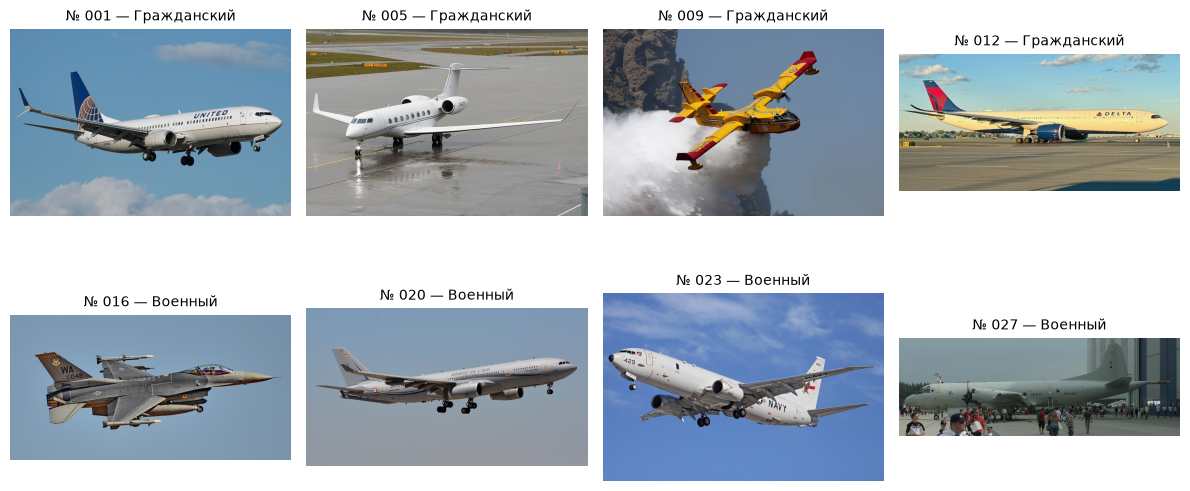

In [6]:
# Примеры обоих классов
example_ids = ['001', '005', '009', '012', '016', '020', '023', '027']
examples = [(k, ae.IMAGES / f'{k}.jpg') for k in example_ids if (ae.IMAGES / f'{k}.jpg').exists()]
if examples:
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for ax in axes.ravel():
        ax.axis('off')
    for ax, (item_id, pic) in zip(axes.ravel(), examples):
        with Image.open(pic) as img:
            ax.imshow(img)
        item = df[df['id'] == item_id].iloc[0]
        ax.set_title(f'№ {item_id} — {ru_label[item["label"]]}', fontsize=10)
    plt.tight_layout()
    plt.show()
else:
    print('Изображения ещё не загружены.')

## 4. Ответы моделей через Ollama API

Обеим моделям передаётся одинаковое изображение размером не более 512 px и одна инструкция. Название самолёта, метка класса, URL и комментарии из CSV **в запрос не включаются**. Ответы записываются после каждого запроса в `outputs/predictions.csv`.

In [7]:
if RUN_INFERENCE:
    ae.check_models(MODEL_IDS)
    predictions = ae.run_inference(
        df, model_ids=MODEL_IDS, limit=MAX_IMAGES,
        force=FORCE_RERUN, timeout_s=360,
    )
else:
    prediction_file = ae.OUT / 'predictions.csv'
    predictions = pd.read_csv(prediction_file, dtype={'id': str}).fillna('') if prediction_file.exists() else None


if predictions is not None and len(predictions):
    predictions = predictions[predictions['model_name'].isin(MODEL_IDS)].copy()
    display_cols = ['id', 'aircraft', 'model_name', 'truth', 'predicted', 'status', 'latency_s']
    results_ru = predictions[display_cols].copy()
    for label_column in ['truth', 'predicted']:
        results_ru[label_column] = results_ru[label_column].map(ru_label).fillna('Нет ответа')
    results_ru['status'] = results_ru['status'].map(ae.STATUS_RU).fillna('Неизвестно')
    results_ru.columns = ['№', 'Самолёт', 'Модель', 'Правильный класс', 'Ответ модели', 'Статус', 'Время, с']
    display(results_ru.tail(12))

else:
    print('Ответов моделей пока нет.')


=== qwen2.5vl:3b (fb90415cde1e) ===

=== gemma3:4b (68ceab7e468a) ===
Обработано 60 запросов из 60, из кэша: 60.


,№,Самолёт,Модель,Правильный класс,Ответ модели,Статус,"Время, с"
48,019,Boeing E-3C Sentry AWACS (USAF),qwen2.5vl:3b,Военный,Военный,Успешно,15.043
49,020,Airbus A330 MRTT (French Air Force),qwen2.5vl:3b,Военный,Военный,Успешно,15.923
50,021,Beechcraft C-12 Huron (USAF),qwen2.5vl:3b,Военный,Военный,Успешно,18.872
51,022,Boeing C-40A Clipper (US Navy),qwen2.5vl:3b,Военный,Военный,Успешно,15.113
52,023,Boeing P-8 Poseidon (US Navy),qwen2.5vl:3b,Военный,Военный,Успешно,16.240
53,024,Lockheed C-130 Hercules (USAF),qwen2.5vl:3b,Военный,Военный,Успешно,17.481
54,025,Boeing C-17 Globemaster III (USAF),qwen2.5vl:3b,Военный,Военный,Успешно,16.401
55,026,Beechcraft T-6 Texan II (USAF),qwen2.5vl:3b,Военный,Гражданский,Успешно,27.316
56,027,Lockheed P-3C Orion (German Navy),qwen2.5vl:3b,Военный,Военный,Успешно,17.714
57,028,Lockheed U-2 Dragon Lady (USAF),qwen2.5vl:3b,Военный,Военный,Успешно,20.306


## 5. Качество классификации

Основные метрики: Accuracy, macro-Precision, macro-Recall, macro-F1, полнота ответов и матрица ошибок. Полная Accuracy указана **только для 30 валидных ответов**. При меньшем количестве отображается отдельно оценка по доступным ответам.

**Важно:** корректность JSON и возможность извлечь класс — разные показатели. Если модель указала однозначную метку `label`, но оборвала поле `reason`, метка учитывается в классификации, а ответ остаётся некорректным JSON. Оригинальный текст сохраняется в `outputs/predictions.csv`.

In [8]:
if predictions is not None and len(predictions):
    metrics, comparison, paired = ae.save_metrics(predictions, df, model_ids=MODEL_IDS)
    metrics_ru = metrics[['model', 'n_valid', 'coverage', 'accuracy_all_30', 'accuracy_on_valid',
                          'precision_macro_valid', 'recall_macro_valid', 'f1_macro_valid',
                          'median_latency_s_valid']].copy()
    metrics_ru.columns = ['Модель', 'Ответов из 30', 'Доля ответов', 'Accuracy (30 фото)',
                          'Accuracy (валидные)', 'Precision (macro)', 'Recall (macro)',
                          'F1 (macro)', 'Медиана времени, с']
    display(metrics_ru.round(3))

else:
    metrics = comparison = paired = None
    print('Метрики появятся после реальных ответов моделей.')

,Модель,Ответов из 30,Доля ответов,Accuracy (30 фото),Accuracy (валидные),Precision (macro),Recall (macro),F1 (macro),"Медиана времени, с"
0,qwen2.5vl:3b,30,1.0,0.967,0.967,0.969,0.967,0.967,15.118
1,gemma3:4b,30,1.0,1.000,1.000,1.000,1.000,1.000,12.324


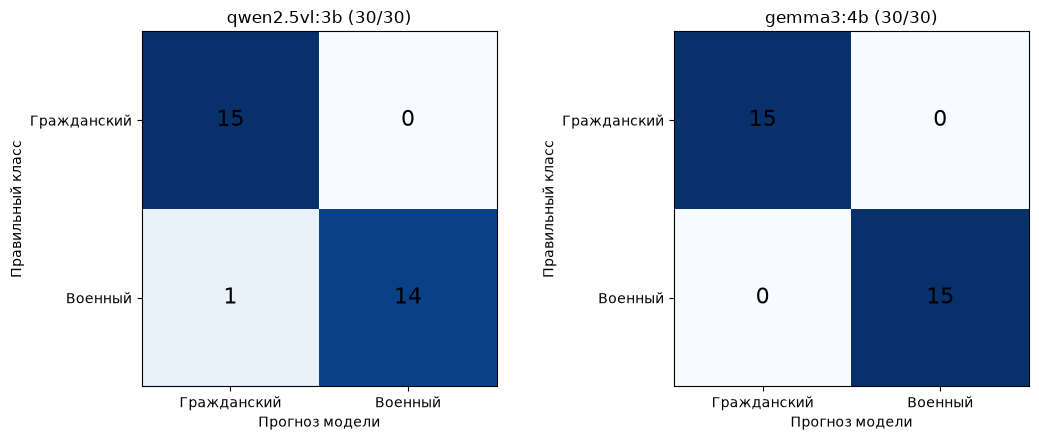

In [9]:
if metrics is not None:
    fig, axes = plt.subplots(1, len(metrics), figsize=(5.5 * len(metrics), 4.5))
    for ax, (_, row) in zip(np.atleast_1d(axes), metrics.iterrows()):
        matrix = np.array([[row['TN'], row['FP']], [row['FN'], row['TP']]], dtype=int)
        ax.imshow(matrix, cmap='Blues')
        for (y, x), value in np.ndenumerate(matrix):
            ax.text(x, y, str(value), ha='center', va='center', fontsize=16)
        ax.set_xticks([0, 1], ['Гражданский', 'Военный'])
        ax.set_yticks([0, 1], ['Гражданский', 'Военный'])
        ax.set_xlabel('Прогноз модели')
        ax.set_ylabel('Правильный класс')
        ax.set_title(f'{row["model"]} ({int(row["n_valid"])}/30)')
    plt.tight_layout()
    plt.savefig(ae.OUT / 'confusion_matrices.png', dpi=150, bbox_inches='tight')
    plt.show()

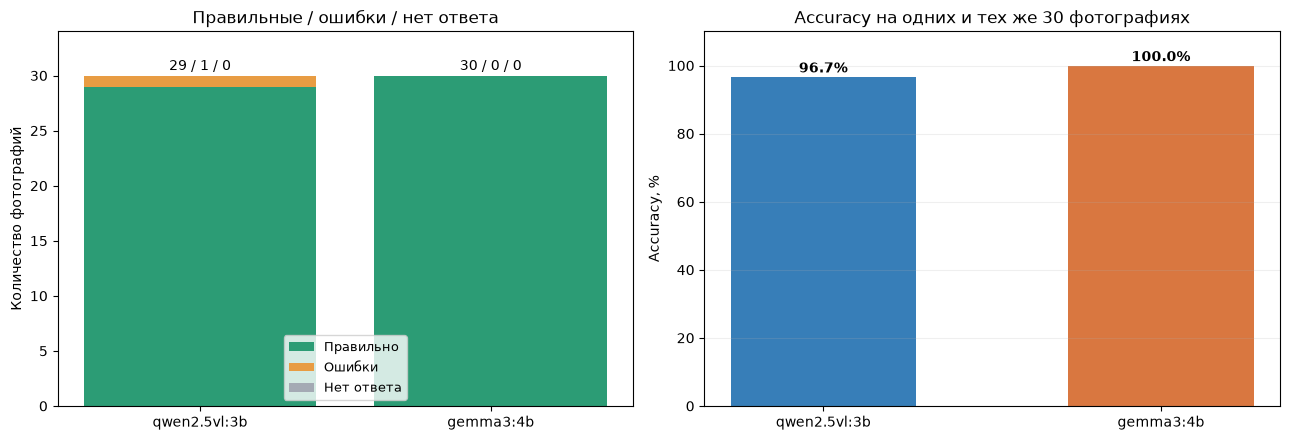

In [10]:
# Честное сравнение: общие фотографии + полнота ответов.
if metrics is not None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    names = metrics['model'].tolist()
    x = np.arange(len(names))
    valid = metrics['n_valid'].astype(int).to_numpy()
    correct = np.rint(metrics['accuracy_on_valid'].fillna(0).to_numpy() * valid).astype(int)
    incorrect = valid - correct
    missing = 30 - valid
    axes[0].bar(x, correct, label='Правильно', color='#2c9c75')
    axes[0].bar(x, incorrect, bottom=correct, label='Ошибки', color='#e89c43')
    axes[0].bar(x, missing, bottom=valid, label='Нет ответа', color='#a4aab4')
    for i in range(len(x)):
        axes[0].text(x[i], 30.5, f'{correct[i]} / {incorrect[i]} / {missing[i]}', ha='center', fontsize=10)
    axes[0].set_xticks(x, names)
    axes[0].set_ylim(0, 34)
    axes[0].set_ylabel('Количество фотографий')
    axes[0].set_title('Правильные / ошибки / нет ответа')
    axes[0].legend(loc='lower center', fontsize=9)
    if paired is not None and len(paired):
        common = len(paired)
        acc_common = [float((paired['pred_a'] == paired['label']).mean()),
                      float((paired['pred_b'] == paired['label']).mean())]
        bars = axes[1].bar(x, [v*100 for v in acc_common], color=['#377eb8','#d97740'], width=.55)
        for bar, value in zip(bars, acc_common):
            axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.3,
                         f'{value:.1%}', ha='center', fontweight='bold')
        axes[1].set_title(f'Accuracy на одних и тех же {common} фотографиях')
        axes[1].set_ylabel('Accuracy, %')
        axes[1].set_ylim(0, 110)
        axes[1].set_xticks(x, names)
        axes[1].grid(axis='y', alpha=.2)

    else:
        axes[1].text(.5, .5, 'Нет общих валидных ответов', ha='center', transform=axes[1].transAxes)
        axes[1].axis('off')
    plt.tight_layout()
    plt.savefig(ae.OUT / 'model_comparison.png', dpi=170, bbox_inches='tight')
    plt.show()


## 6. Анализ сложных случаев и выводы

Сравнение выполняется на одних и тех же фотографиях; в таблице ниже показаны ошибки и разногласия. Для небольшой направленно сложной выборки результаты носят иллюстративный характер.

В итоговой таблице отдельно сравниваются извлечённые классы и доля корректных JSON-ответов. Это позволяет не путать ошибки формата с ошибками классификации.

In [11]:
# Показываем разногласия, ошибки и отсутствующие ответы на всех 30 снимках.
if predictions is not None and len(predictions):
    review = df[['id', 'aircraft', 'label', 'difficulty']].copy()
    for model, col in zip(MODEL_IDS, ['Ответ Qwen', 'Ответ Gemma']):
        sub = predictions[predictions['model_name'] == model][['id', 'predicted', 'status']].drop_duplicates('id', keep='last')
        sub = sub.rename(columns={'predicted': col, 'status': col + ' (статус)'})
        review = review.merge(sub, on='id', how='left')
        review[col] = review[col].map(ru_label).fillna('Нет ответа')
        review.loc[review[col + ' (статус)'] != 'ok', col] = 'Нет ответа'
    review['Эталон'] = review['label'].map(ru_label)
    review['Сложность'] = review['difficulty'].map(ru_difficulty)
    focus = review[(review['Ответ Qwen'] != review['Эталон']) |
                   (review['Ответ Gemma'] != review['Эталон']) |
                   (review['Ответ Qwen'] != review['Ответ Gemma'])]
    display(focus[['id', 'aircraft', 'Эталон', 'Сложность', 'Ответ Qwen', 'Ответ Gemma']].rename(columns={'id':'№', 'aircraft':'Самолёт'}))
    print(f'Проблемные фотографии: {len(focus)} из {len(review)}.')
else:
    print('Ответы моделей ещё не получены.')


,№,Самолёт,Эталон,Сложность,Ответ Qwen,Ответ Gemma
25,026,Beechcraft T-6 Texan II (USAF),Военный,Сложный,Гражданский,Военный


Проблемные фотографии: 1 из 30.


In [12]:
if predictions is not None and len(predictions):
    summary = ae.format_summary(predictions, df, model_ids=MODEL_IDS)
    display(summary.round(3))
else:
    print('После запуска моделей здесь появится итоговая таблица.')

,model,n_total,n_labels,correct_labels,accuracy_extracted,json_valid_count,json_valid_share
0,qwen2.5vl:3b,30,30,29,0.967,30,1.000
1,gemma3:4b,30,30,30,1.000,28,0.933


### Вывод

В ходе работы сравнивалось две мультимодальные модели — Qwen2.5-VL 3B и Gemma 3 4B — на выборке из 30 фотографий военных и гражданских самолётов. Обе модели запускались локально через Ollama и получали одинаковые изображения и инструкции.

Qwen2.5-VL правильно определила класс 29 из 30 фотографий, показав точность 96,67%. 
Gemma 3 правильно классифицировала все 30 изображений, достигнув точности 100%.

При этом модели по-разному соблюдали требуемый формат ответа. Qwen сформировала 30 корректных JSON-ответов, а Gemma — 28. В двух остальных случаях Gemma указала правильный класс, но не завершила JSON корректно. Эти ответы удалось обработать с помощью дополнительного извлечения метки, сохранив исходный текст.

Таким образом, на данной выборке Gemma показала более высокую точность классификации, а Qwen — более стабильное соблюдение формата ответа.